# Antecipação de Recebíveis da Olist

Análise da agenda de recebíveis com dados até **2018-06-30** (dataset público da Olist, [Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)) mostrando alguns insights: onde está a agenda, quem espera muito tempo para receber, como os lojistas se segmentam — e o que a segmentação de clientes definida previamente por regra de negócio ganhou ao ser validada por k-means.

Pipeline bronze → silver → gold construído em Python, PySpark e SQL no Databricks. Análise Exploratória e Machine Learning com segmentação de clientes (lojistas) através de clusters.

## 1. A pergunta de negócio

Vendas no crédito parcelado geram recebíveis futuros (a parcela k de uma venda liquida em D+30·k). O lojista tem que esperar para receber esse crédito, mas a plataforma de adquirência pode antecipar (**essa agenda em aberto é o estoque do produto**).

As células abaixo mostram os insights obtidos das tabelas gold.

In [0]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

metricas = spark.table("workspace.olist.gold_seller_metricas").toPandas()
segmentos = spark.table("workspace.olist.gold_segmento_resumo").toPandas()

com_agenda = (metricas["agenda_aberta"] > 0).sum()
prazo_ponderado = (
    (metricas["tpv_credito"] * metricas["prazo_medio_contratado_dias"]).sum()
    / metricas.loc[metricas["prazo_medio_contratado_dias"].notna(), "tpv_credito"].sum()
)

print(f"Lojistas com venda até 2018-06-30 ....... {len(metricas):>10,.0f}")
print(f"Agenda em aberto (a receber) ............ R$ {metricas['agenda_aberta'].sum():>10,.0f}")
print(f"Lojistas com agenda em aberto ............ {com_agenda:>10,.0f}  ({com_agenda / len(metricas):.0%} da base)")
print(f"Prazo médio contratado no crédito ....... {prazo_ponderado:>10,.0f} dias (ponderado por TPV)")

Lojistas com venda até 2018-06-30 .......      2,717
Agenda em aberto (a receber) ............ R$  2,432,862
Lojistas com agenda em aberto ............      1,751  (64% da base)
Prazo médio contratado no crédito .......         90 dias (ponderado por TPV)


## 2. A agenda é concentrada

Poucos lojistas concentram quase toda a agenda como mostra a curva de Pareto. Com isso temos duas consequências: enquanto os grandes lojistas precisam de negociação ativa (taxas e limites), a cauda longa só faz sentido com planos **self-service** de baixo custo de aquisição.

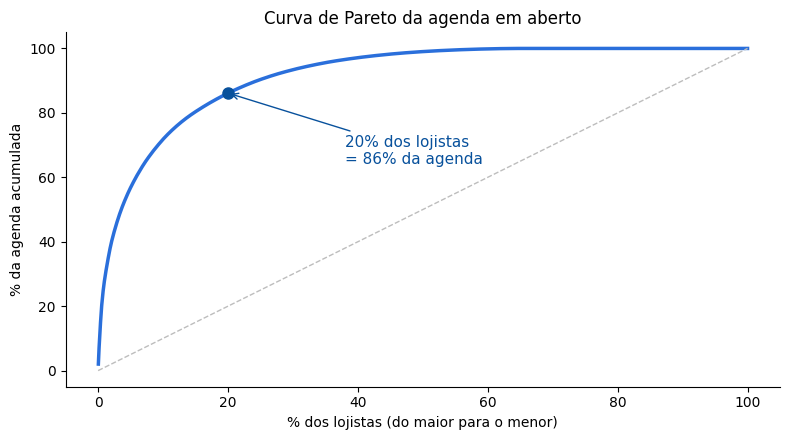

In [0]:
valores = np.sort(metricas["agenda_aberta"].fillna(0).to_numpy())[::-1]
frac_lojistas = np.arange(1, len(valores) + 1) / len(valores)
frac_agenda = np.cumsum(valores) / valores.sum()
top20 = frac_agenda[np.searchsorted(frac_lojistas, 0.20)]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(frac_lojistas * 100, frac_agenda * 100, color="#2a6fdb", lw=2.5)
ax.plot([0, 100], [0, 100], ls="--", color="#bdbdbd", lw=1)
ax.plot(20, top20 * 100, "o", color="#08519c", ms=8)
ax.annotate(
    f"20% dos lojistas\n= {top20:.0%} da agenda",
    xy=(20, top20 * 100), xytext=(38, top20 * 100 - 22),
    arrowprops=dict(arrowstyle="->", color="#08519c"), color="#08519c", fontsize=11,
)
ax.set_xlabel("% dos lojistas (do maior para o menor)")
ax.set_ylabel("% da agenda acumulada")
ax.set_title("Curva de Pareto da agenda em aberto")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Onde a espera dói

Categorias de ticket alto, muito parceladas e com prazo contratado de 3 a 5 meses dominam a agenda. São os alvos naturais da antecipação: cada real antecipado desbloqueia muitas semanas de espera.

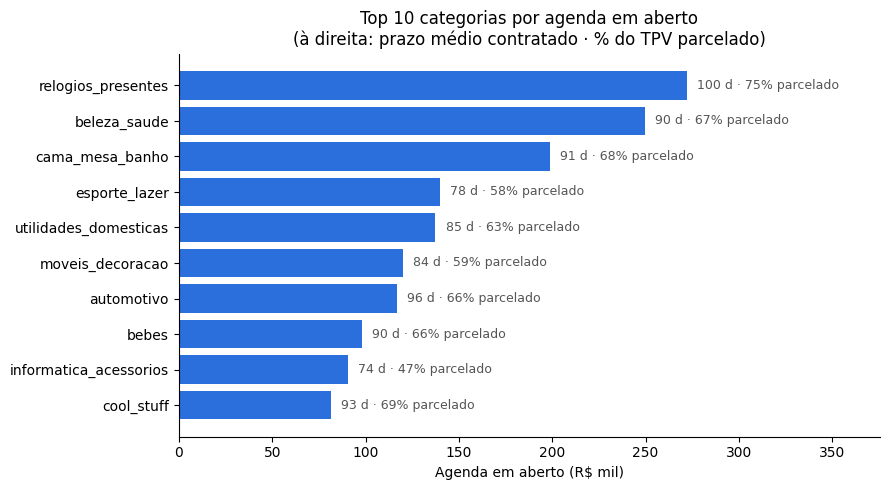

In [0]:
cat = (
    spark.table("workspace.olist.gold_categoria_resumo").toPandas()
    .nlargest(10, "agenda_aberta")
    .sort_values("agenda_aberta")
)
xmax = cat["agenda_aberta"].max() / 1e3

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(cat["categoria"], cat["agenda_aberta"] / 1e3, color="#2a6fdb")
for i, (pr, pc) in enumerate(zip(cat["prazo_medio_contratado_dias"], cat["pct_credito_parcelado"])):
    ax.text(cat["agenda_aberta"].iloc[i] / 1e3 + xmax * 0.02, i, f"{pr:.0f} d · {pc:.0%} parcelado",
            va="center", fontsize=9, color="#555555")
ax.set_xlim(0, xmax * 1.38)
ax.set_xlabel("Agenda em aberto (R$ mil)")
ax.set_title("Top 10 categorias por agenda em aberto\n(à direita: prazo médio contratado · % do TPV parcelado)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Recorrência é exceção

A maioria dos lojistas não sustenta a atividade: meses depois da primeira venda, boa parte não volta a vender. Para antecipação isso importa duas vezes - quem some não renova a agenda, e quem tem pouca história não aguenta limite alto.

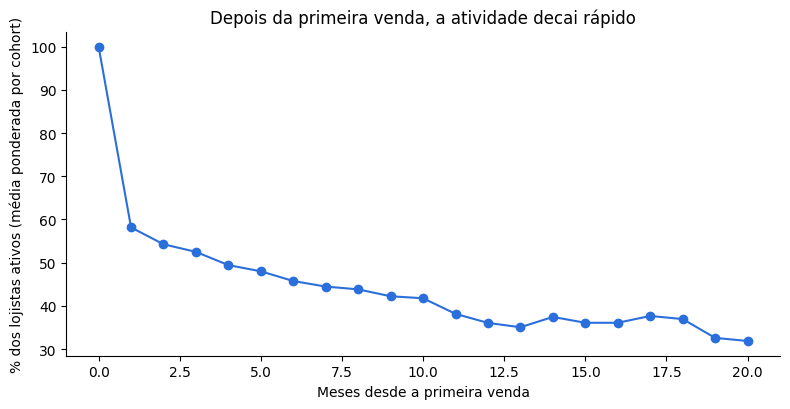

Mês 1: 58.2% dos lojistas ativos
Mês 3: 52.5% dos lojistas ativos
Mês 6: 45.8% dos lojistas ativos


In [0]:
coh = spark.table("workspace.olist.gold_cohort_sellers").toPandas()
ativ = (
    coh.assign(w=coh["pct_ativos"] * coh["tamanho_cohort"])
    .groupby("meses_desde")[["w", "tamanho_cohort"]]
    .sum()
    .assign(pct_ativos=lambda d: d["w"] / d["tamanho_cohort"])
)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ativ.index, ativ["pct_ativos"] * 100, marker="o", color="#2a6fdb")
ax.set_xlabel("Meses desde a primeira venda")
ax.set_ylabel("% dos lojistas ativos (média ponderada por cohort)")
ax.set_title("Depois da primeira venda, a atividade decai rápido")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for m in (1, 3, 6):
    if m in ativ.index:
        print(f"Mês {m}: {ativ.loc[m, 'pct_ativos']:.1%} dos lojistas ativos")

## 5. Cinco segmentos por regra - cada um com um tratamento

A regra avalia os critérios **em ordem** (o primeiro atendido define o segmento). O gráfico mostra a diferença entre volume de lojistas e valor da agenda:

| Segmento | Tratamento sugerido |
| --- | --- |
| Grandes parceladores (top 20% agenda, > 50% TPV parcelado) | Negociação ativa: taxas e limites personalizados |
| À vista (< 20% parcelado) | Fora do foco: quase não geram agenda |
| Médios recorrentes (3+ meses ativos) | Antecipação automática, melhor alvo |
| Grandes ocasionais (agenda, > 50% parcelado, prazo ≥ 90 d) | Antecipação com limite inicial conservador |
| Pequenos ou esporádicos | Self-service de baixo custo |

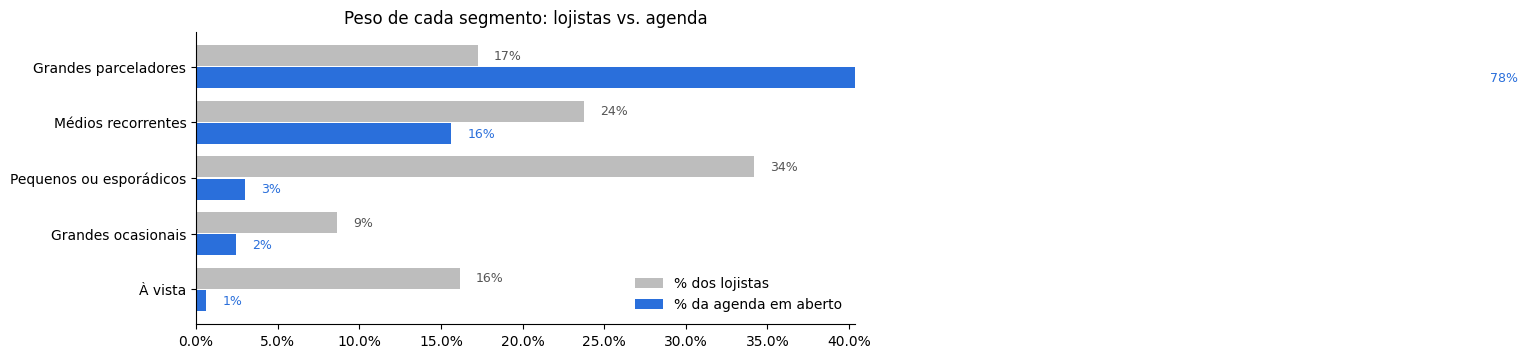

In [0]:
res = segmentos.sort_values("pct_agenda")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = np.arange(len(res))
ax.barh(y + 0.2, res["pct_lojistas"], height=0.38, color="#bdbdbd", label="% dos lojistas")
ax.barh(y - 0.2, res["pct_agenda"], height=0.38, color="#2a6fdb", label="% da agenda em aberto")
for i, (pl, pa) in enumerate(zip(res["pct_lojistas"], res["pct_agenda"])):
    ax.text(pl + 0.01, i + 0.2, f"{pl:.0%}", va="center", fontsize=9, color="#555555")
    ax.text(pa + 0.01, i - 0.2, f"{pa:.0%}", va="center", fontsize=9, color="#2a6fdb")
ax.set_yticks(y)
ax.set_yticklabels(res["segmento_regra"])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, res["pct_lojistas"].max() * 1.18)
ax.set_title("Peso de cada segmento: lojistas vs. agenda")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 6. O que o k-means validou, e o que mudou

O k-means agrupou 1.875 lojistas qualificados (≥ 3 pedidos) em 3 clusters de comportamento. A concordância com a regra (ARI = 0,30) é baixa por construção - o valor está nas **diferenças**:

* O cluster **“Grandes vendas, longa espera”** (25% dos lojistas, 38% da agenda, ticket R$ 309, 114 dias de espera, só 2 meses ativos) aparecia espalhado entre “Pequenos ou esporádicos” e “Grandes parceladores”.
* Diante disso, a regra ganhou o **5º segmento - Grandes ocasionais** (agenda + > 50% parcelado + prazo ≥ 90 dias): 234 lojistas, R$ 59,9 mil de agenda, ~115 dias de espera e ~1 mês ativo.
* Recomendação: antecipação para esse grupo com **limite inicial travado** (devido histórico curto), liberando conforme o lojista volta a vender.

O ARI subiu de 0,27 para 0,30 com o novo segmento - e, mais importante, a regra parou de tratar lojista de venda grande como “pequeno”.

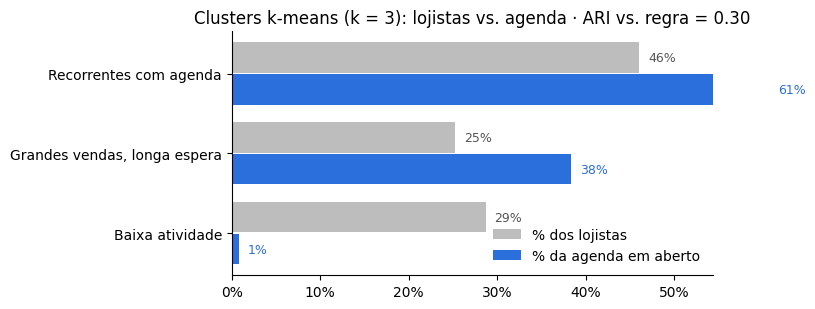

In [0]:
perf = spark.table("workspace.olist.gold_cluster_perfil").toPandas()
ari = perf["ari_vs_regra"].iloc[0]
res = perf.sort_values("pct_agenda")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
y = np.arange(len(res))
ax.barh(y + 0.2, res["pct_lojistas"], height=0.38, color="#bdbdbd", label="% dos lojistas")
ax.barh(y - 0.2, res["pct_agenda"], height=0.38, color="#2a6fdb", label="% da agenda em aberto")
for i, (pl, pa) in enumerate(zip(res["pct_lojistas"], res["pct_agenda"])):
    ax.text(pl + 0.01, i + 0.2, f"{pl:.0%}", va="center", fontsize=9, color="#555555")
    ax.text(pa + 0.01, i - 0.2, f"{pa:.0%}", va="center", fontsize=9, color="#2a6fdb")
ax.set_yticks(y)
ax.set_yticklabels(res["cluster_nome"])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, res["pct_lojistas"].max() * 1.18)
ax.set_title(f"Clusters k-means (k = 3): lojistas vs. agenda · ARI vs. regra = {ari:.2f}")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Apêndice A. Pipeline e tabelas gold

Bronze → silver → gold no catálogo `workspace.olist`, data de corte 2018-06-30, janela de 6 meses. Fonte: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle).

| Tabela gold | Conteúdo |
| --- | --- |
| `gold_seller_metricas` | Uma linha por lojista: TPV, mix de pagamento, agenda em aberto, prazo, ticket, meses ativos |
| `gold_seller_segmento` | Segmento por regra de cada lojista (5 segmentos) |
| `gold_segmento_resumo` | Perfil agregado por segmento |
| `gold_categoria_resumo` | Mix, agenda e prazo por categoria de produto |
| `gold_cohort_sellers` | Atividade por cohort (mês da primeira venda) |
| `gold_seller_cluster` | Cluster k-means de cada lojista qualificado + variáveis usadas |
| `gold_cluster_perfil` | Perfil agregado por cluster, com k e ARI vs. regra |

A agenda foi construída por uma regra de negócio: a parcela k de uma venda no crédito liquida em D+30·k; “em aberto” é tudo com liquidação após a data de corte.

## Apêndice B. Regra de segmentação (ordem de avaliação)

| Ordem | Segmento | Critério |
| --- | --- | --- |
| 1 | Grandes parceladores | Top 20% por agenda em aberto **e** > 50% do TPV parcelado |
| 2 | À vista | < 20% do TPV parcelado |
| 3 | Médios recorrentes | Vendas em pelo menos 3 dos últimos 6 meses |
| 4 | Grandes ocasionais | Agenda em aberto **e** > 50% do TPV parcelado **e** prazo médio contratado ≥ 90 dias |
| 5 | Pequenos ou esporádicos | O restante |

O 4º critério foi aberto após a validação por k-means (slide 6): separa o esporádico de venda grande e espera longa do esporádico pequeno. Os cortes ficam na célula de configuração dos notebooks de análise.

## Apêndice C. Método do k-means

* **Base:** 1.875 de 2.717 lojistas (69%) — exigência de ≥ 3 pedidos para que ticket e % parcelado não sejam ruído; o restante entra no dashboard como “sem histórico suficiente”.
* **Variáveis (padronizadas):** log(agenda em aberto), prazo médio contratado, log(ticket médio), meses ativos na janela, % do TPV parcelado.
* **k = 3** pela maior silhouette (0,291); cotovelo e leitura de negócio confirmam. Renumeração estável por agenda mediana decrescente.
* **Clusters:** Recorrentes com agenda (864 lojistas, 61% da agenda) · Grandes vendas, longa espera (473, 38%) · Baixa atividade (538, 0,8%).
* **PCA (visual):** componente 1 ≈ porte/tamanho da operação; componente 2 ≈ recorrência.
* **ARI regra vs. k-means:** 0,30 (antes do 5º segmento: 0,27). ARI baixo não é erro: a regra usa cortes de negócio, o k-means usa distância.

## Apêndice D. Limitações da análise

* **Sem premissas de mercado:** o estudo não assume taxa, MDR ou custo de captação de dinheiro; “antecipar” é avaliado por valor e espera, não por margem.
* **Janela e corte:** dados até 2018-06-30, janela de 6 meses - sazonalidade e crescimento posteriores não capturados.
* **Histórico curto:** “Grandes ocasionais” tem ~1 mês ativo na janela; limite de crédito precisaria começar conservador.